# GAD-7 Regression RL Model: 4 Learning Rates (Task $\times$ Valence) (`16`)

This notebook extends the winning 4-learning-rate model (**Model 4: `Task x Valence`** from Notebook 05) and tests whether generalized anxiety symptoms (GAD-7) linearly predict each of the four learning rates when between-subject variation in $\alpha$ is driven strictly by GAD-7:
- $\alpha_{win,pos}(i) = \text{invlogit}(\text{intercept}_{win,pos} + \text{slope}_{win,pos} \cdot \text{GAD7}_{\text{norm}, i})$ *(Win domain, Positive PE)*
- $\alpha_{win,neg}(i) = \text{invlogit}(\text{intercept}_{win,neg} + \text{slope}_{win,neg} \cdot \text{GAD7}_{\text{norm}, i})$ *(Win domain, Negative PE)*
- $\alpha_{lose,pos}(i) = \text{invlogit}(\text{intercept}_{lose,pos} + \text{slope}_{lose,pos} \cdot \text{GAD7}_{\text{norm}, i})$ *(Loss domain, Positive PE)*
- $\alpha_{lose,neg}(i) = \text{invlogit}(\text{intercept}_{lose,neg} + \text{slope}_{lose,neg} \cdot \text{GAD7}_{\text{norm}, i})$ *(Loss domain, Negative PE)*

Sampled using **PyMC v6 (`nutpie`)** with the subject-vectorized 2D `pytensor.scan` loop.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy import stats
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_m4_vec, get_hdi_bounds, plot_posterior_hdi

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data and Vectorize across Subjects
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey', 'GAD7']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub}")
print(f"Total trials: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects included: 67
Total trials: 6520 (Vectorized scan length: 100 steps)


In [3]:
def build_gad7_4alpha_model(vdata, gad7_normalized):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m_gad7_4a:
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        alphas = {}
        for name in ['win_pos', 'win_neg', 'lose_pos', 'lose_neg']:
            intercept = pm.Normal(f'intercept_{name}', mu=0, sigma=1.5)
            slope = pm.Normal(f'slope_{name}', mu=0, sigma=1.5)
            alphas[name] = pm.Deterministic(f'alpha_{name}', pm.math.invlogit(intercept + slope * gad7_data))
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=0, sigma=2.0)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=1.0)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m4_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['win_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alphas['win_pos'], alphas['win_neg'], alphas['lose_pos'], alphas['lose_neg']],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m_gad7_4a

print("Building vectorized 4-Alpha GAD-7 model...")
m_gad7_4a = build_gad7_4alpha_model(vdata, gad7_normalized)


Building vectorized 4-Alpha GAD-7 model...


In [4]:
print("Sampling posterior using nutpie (PyMC 6)...")
with m_gad7_4a:
    idata = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using nutpie (PyMC 6)...


NUTS[nutpie]: [intercept_win_pos, slope_win_pos, intercept_win_neg, slope_win_neg, intercept_lose_pos, slope_lose_pos, intercept_lose_neg, slope_lose_neg, mu_beta_log, sigma_beta, beta_raw]


Output()

Sampling complete!


4-ALPHA (TASK x VALENCE) GAD-7 REGRESSION RESULTS (89% HDI)
Win Domain - Positive PE (alpha_win_pos)     | Mean = +2.889 | 89% HDI [+1.715, +4.125] -> EXCLUDES 0 (Credible effect at 89%)
Win Domain - Negative PE (alpha_win_neg)     | Mean = +1.408 | 89% HDI [+0.398, +2.424] -> EXCLUDES 0 (Credible effect at 89%)
Loss Domain - Positive PE (alpha_lose_pos)   | Mean = +0.373 | 89% HDI [-1.177, +1.991] -> INCLUDES 0 (Not strictly credible at 89%)
Loss Domain - Negative PE (alpha_lose_neg)   | Mean = -0.536 | 89% HDI [-1.436, +0.261] -> INCLUDES 0 (Not strictly credible at 89%)



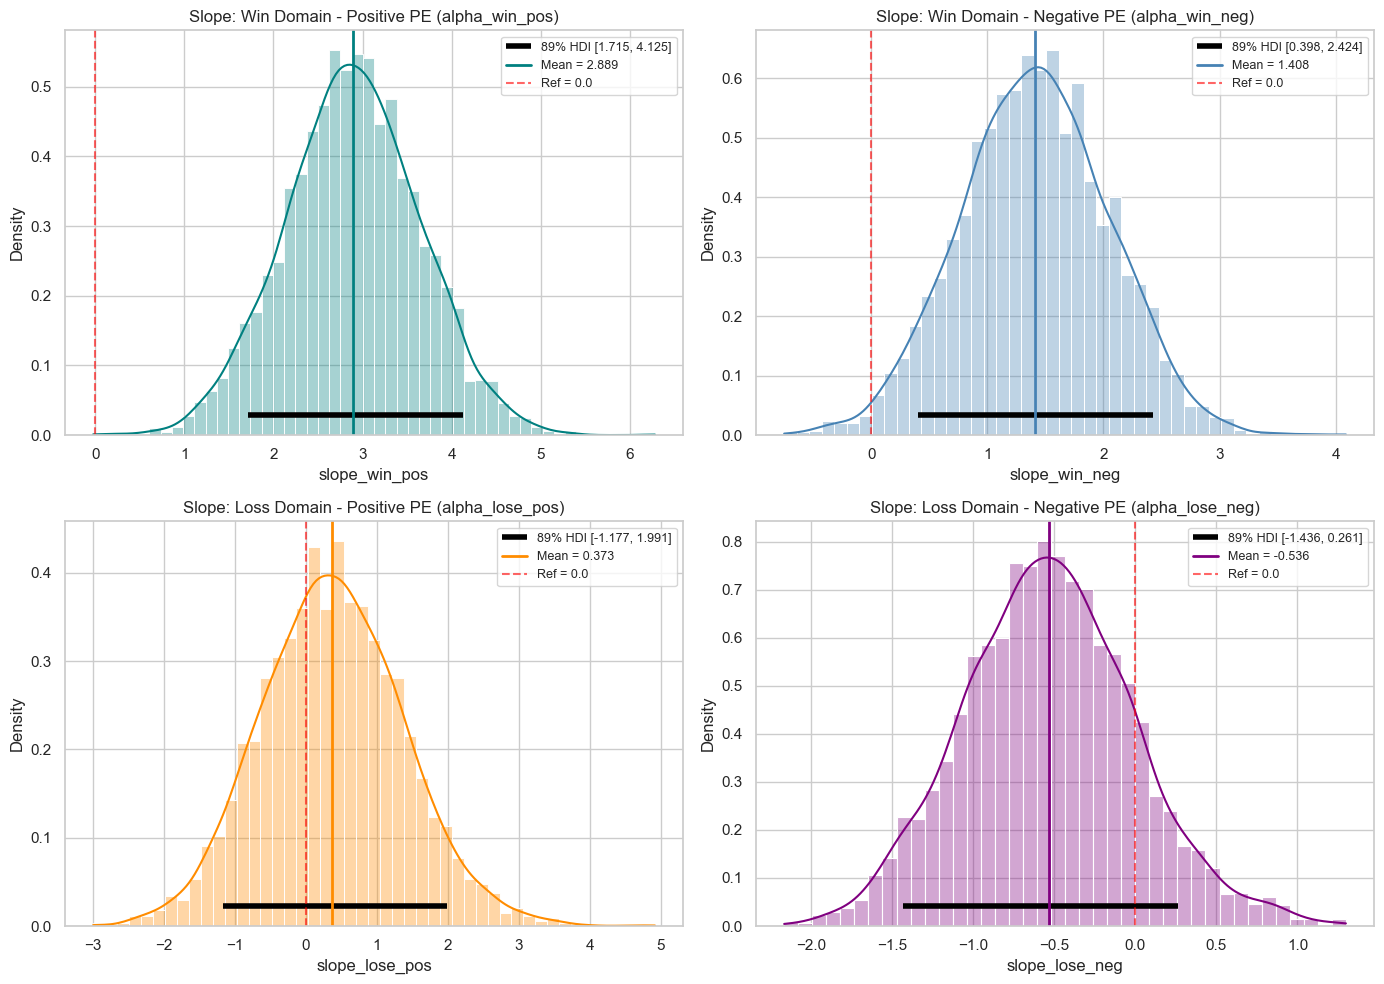

In [5]:
param_info = [
    ('slope_win_pos', 'alpha_win_pos', 'Win Domain - Positive PE (alpha_win_pos)', 'teal'),
    ('slope_win_neg', 'alpha_win_neg', 'Win Domain - Negative PE (alpha_win_neg)', 'steelblue'),
    ('slope_lose_pos', 'alpha_lose_pos', 'Loss Domain - Positive PE (alpha_lose_pos)', 'darkorange'),
    ('slope_lose_neg', 'alpha_lose_neg', 'Loss Domain - Negative PE (alpha_lose_neg)', 'purple'),
]

print("==========================================================================")
print("4-ALPHA (TASK x VALENCE) GAD-7 REGRESSION RESULTS (89% HDI)")
print("==========================================================================")
for slope_var, alpha_var, label, _ in param_info:
    low, high = get_hdi_bounds(idata, slope_var, prob=0.89)
    mean_val = float(idata.posterior[slope_var].values.mean())
    includes_zero = (low <= 0) and (high >= 0)
    status = "INCLUDES 0 (Not strictly credible at 89%)" if includes_zero else "EXCLUDES 0 (Credible effect at 89%)"
    print(f"{label:44s} | Mean = {mean_val:+.3f} | 89% HDI [{low:+.3f}, {high:+.3f}] -> {status}")
print("==========================================================================\n")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (slope_var, alpha_var, label, color) in zip(axes.flatten(), param_info):
    plot_posterior_hdi(idata, slope_var, prob=0.89, ax=ax, color=color, title=f"Slope: {label}")
plt.tight_layout()
plt.show()


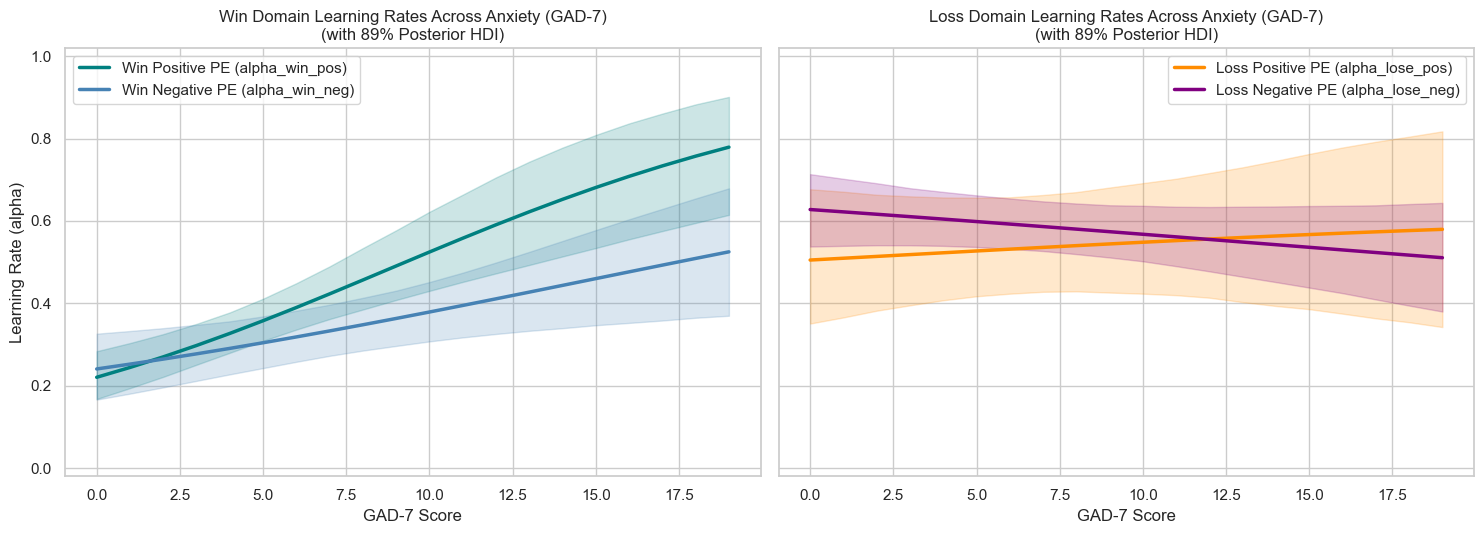

In [6]:
# Plot Predicted 4 Learning Rates Across GAD-7 Scores (with 89% Posterior HDI)
sort_idx = np.argsort(gad7_scores)
g_sorted = gad7_scores[sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

# Win Domain Panel
for alpha_var, label, color in [('alpha_win_pos', 'Win Positive PE (alpha_win_pos)', 'teal'),
                                ('alpha_win_neg', 'Win Negative PE (alpha_win_neg)', 'steelblue')]:
    samples = idata.posterior[alpha_var].values.reshape(-1, n_sub)[:, sort_idx]
    mean_curve = samples.mean(axis=0)
    hdi_curve = np.quantile(samples, [0.055, 0.945], axis=0).T
    axes[0].plot(g_sorted, mean_curve, color=color, lw=2.5, label=label)
    axes[0].fill_between(g_sorted, hdi_curve[:, 0], hdi_curve[:, 1], color=color, alpha=0.2)

axes[0].set_title("Win Domain Learning Rates Across Anxiety (GAD-7)\n(with 89% Posterior HDI)")
axes[0].set_xlabel("GAD-7 Score")
axes[0].set_ylabel("Learning Rate (alpha)")
axes[0].set_ylim(-0.02, 1.02)
axes[0].legend(loc='best')

# Loss Domain Panel
for alpha_var, label, color in [('alpha_lose_pos', 'Loss Positive PE (alpha_lose_pos)', 'darkorange'),
                                ('alpha_lose_neg', 'Loss Negative PE (alpha_lose_neg)', 'purple')]:
    samples = idata.posterior[alpha_var].values.reshape(-1, n_sub)[:, sort_idx]
    mean_curve = samples.mean(axis=0)
    hdi_curve = np.quantile(samples, [0.055, 0.945], axis=0).T
    axes[1].plot(g_sorted, mean_curve, color=color, lw=2.5, label=label)
    axes[1].fill_between(g_sorted, hdi_curve[:, 0], hdi_curve[:, 1], color=color, alpha=0.2)

axes[1].set_title("Loss Domain Learning Rates Across Anxiety (GAD-7)\n(with 89% Posterior HDI)")
axes[1].set_xlabel("GAD-7 Score")
axes[1].legend(loc='best')

plt.tight_layout()
plt.savefig('../data/alpha_4rates_vs_gad7_nb16.png', dpi=150, bbox_inches='tight')
plt.show()
